# TP Noté
## Réalisé par Andrew CAI et Mathis HEDER


## Imports

In [199]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

# Partie 1

In [4]:
# Chargement des données
data = pd.read_csv("./../data/dataset_qualite_air_brut.csv")
df = pd.DataFrame(data, columns=["id_station","ville","region", "type_zone", "PM25", "PM10", "NO2", "O3", "CO", "SO2", "temperature_c", "humidite_pct", "vitesse_vent_kmh", "densite_trafic", "annee", "indice_IQA", "categorie_IQA"])

# Afficher le dataframe
df

,id_station,ville,region,type_zone,PM25,PM10,NO2,O3,CO,SO2,temperature_c,humidite_pct,vitesse_vent_kmh,densite_trafic,annee,indice_IQA,categorie_IQA
0,438,Toulouse,Occitanie,Périurbain,20.7,52.1,8.2,35.2,0.36,5.7,19.2,44.0,14.3,52277.0,2024,92.0,Moyen
1,369,Paris,Île-de-France,Périurbain,3.2,12.8,52.7,41.0,1.00,8.8,7.8,60.1,32.6,4469.0,2021,84.8,Moyen
2,340,Lille,Hauts-de-France,Urbain,12.7,24.4,10.2,21.7,0.64,2.3,24.0,70.6,2.9,36643.0,2020,45.9,NaN
3,281,Rennes,Bretagne,Rural,NaN,27.3,22.3,NaN,0.35,3.0,5.5,42.6,20.8,14651.0,2020,49.4,??
4,138,Lyon,Auvergne-Rhône-Alpes,Rural,16.0,32.1,1.0,40.2,0.17,0.1,16.5,70.8,23.9,19700.0,2024,42.3,Bon
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
483,202,Marseille,Provence-Alpes-Côte d'Azur,Rural,4.9,2.0,23.5,77.8,NaN,0.3,14.8,66.4,4.8,8941.0,2021,100.1,NaN
484,169,Bordeaux,Nouvelle-Aquitaine,Périurbain,28.7,48.5,950.0,75.4,0.10,2.9,25.2,71.0,5.7,26886.0,2021,NaN,Dégradé
485,186,Nice,Provence-Alpes-Côte d'Azur,Urbain,12.5,14.2,24.3,47.2,1.51,4.6,13.1,61.4,13.4,32598.0,2022,92.7,Moyen
486,36,Nice,Provence-Alpes-Côte d'Azur,Urbain,11.6,18.7,6.9,69.6,1.36,11.1,33.9,27.6,24.4,27205.0,2019,107.4,Dégradé


### Affichez les premières lignes la forme du DataFrame, les types de chaque colonne et les statistiques descriptives de base.


In [5]:
df.head()

,id_station,ville,region,type_zone,PM25,PM10,NO2,O3,CO,SO2,temperature_c,humidite_pct,vitesse_vent_kmh,densite_trafic,annee,indice_IQA,categorie_IQA
0,438,Toulouse,Occitanie,Périurbain,20.7,52.1,8.2,35.2,0.36,5.7,19.2,44.0,14.3,52277.0,2024,92.0,Moyen
1,369,Paris,Île-de-France,Périurbain,3.2,12.8,52.7,41.0,1.00,8.8,7.8,60.1,32.6,4469.0,2021,84.8,Moyen
2,340,Lille,Hauts-de-France,Urbain,12.7,24.4,10.2,21.7,0.64,2.3,24.0,70.6,2.9,36643.0,2020,45.9,NaN
3,281,Rennes,Bretagne,Rural,NaN,27.3,22.3,NaN,0.35,3.0,5.5,42.6,20.8,14651.0,2020,49.4,??
4,138,Lyon,Auvergne-Rhône-Alpes,Rural,16.0,32.1,1.0,40.2,0.17,0.1,16.5,70.8,23.9,19700.0,2024,42.3,Bon


In [13]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 488 entries, 0 to 487
Data columns (total 17 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   id_station        488 non-null    int64  
 1   ville             488 non-null    str    
 2   region            488 non-null    str    
 3   type_zone         488 non-null    str    
 4   PM25              454 non-null    float64
 5   PM10              443 non-null    float64
 6   NO2               452 non-null    float64
 7   O3                457 non-null    float64
 8   CO                439 non-null    float64
 9   SO2               451 non-null    float64
 10  temperature_c     441 non-null    float64
 11  humidite_pct      447 non-null    float64
 12  vitesse_vent_kmh  448 non-null    float64
 13  densite_trafic    443 non-null    float64
 14  annee             488 non-null    int64  
 15  indice_IQA        451 non-null    float64
 16  categorie_IQA     447 non-null    str    
dtypes: float

In [16]:
print("Forme du DataFrame :", df.shape)

Forme du DataFrame : (488, 17)


In [17]:
df.describe()

,id_station,PM25,PM10,NO2,O3,CO,SO2,temperature_c,humidite_pct,vitesse_vent_kmh,densite_trafic,annee,indice_IQA
count,488.000000,454.000000,443.000000,452.000000,457.000000,439.000000,451.000000,441.000000,447.000000,448.000000,443.000000,488.000000,451.000000
mean,239.686475,17.367401,35.747178,31.746018,57.633698,0.742893,5.741020,14.117914,66.331767,16.034821,19214.358916,2021.090164,107.774945
std,138.182936,12.456354,24.700297,78.242491,22.827589,0.631773,5.656884,8.837589,15.649616,11.438979,15693.924828,2.113821,45.302164
min,1.000000,-24.800000,2.000000,1.000000,5.000000,0.100000,0.100000,-62.500000,20.400000,0.200000,100.000000,2018.000000,0.000000
25%,121.750000,8.600000,17.900000,10.200000,40.900000,0.260000,1.700000,9.100000,55.350000,7.175000,8290.000000,2019.000000,76.250000
50%,237.500000,15.700000,30.500000,21.100000,57.900000,0.570000,4.300000,14.200000,67.500000,13.600000,16055.000000,2021.000000,100.900000
75%,359.250000,24.100000,48.250000,34.625000,73.300000,1.050000,8.200000,19.100000,77.100000,22.025000,26184.000000,2023.000000,132.900000
max,480.000000,71.100000,159.400000,950.000000,111.900000,5.070000,42.700000,88.100000,100.000000,69.200000,93804.000000,2035.000000,255.700000


### Ce que l'on remarque
*  Il y a des valeurs manquantes (NaN)
*  "??" à la ligne 5 dans la colonne categorie_IQA
*  Il ya aussi des valeur noté arbitrairement par exemple ("Très moyen" et "très moyen" ou encore "BON" et "Bon" ou encore "NC")

 ## Calculez le nombre et le pourcentage de valeurs manquantes pour chaque colonne.

In [21]:
# Toutes les colonnes du dataframe
df.columns

Index(['id_station', 'ville', 'region', 'type_zone', 'PM25', 'PM10', 'NO2',
       'O3', 'CO', 'SO2', 'temperature_c', 'humidite_pct', 'vitesse_vent_kmh',
       'densite_trafic', 'annee', 'indice_IQA', 'categorie_IQA'],
      dtype='str')

In [25]:
for col in ["ville", "region", "type_zone", "categorie_IQA"]:
    print("_______" + col + "_______")
    print(df[col].value_counts(dropna=False).to_string())
    print("\n")

_______ville_______
ville
Strasbourg    65
Bordeaux      60
Lyon          57
Paris         48
Rennes        46
Nice          43
Toulouse      42
Nantes        41
Marseille     40
Lille         38
paris          1
marseille      1
Nantes.        1
Toulouse       1
Lyon           1
LYON           1
RENNES         1
BORDEAUX       1


_______region_______
region
Provence-Alpes-Côte d'Azur    84
Grand Est                     66
Nouvelle-Aquitaine            60
Auvergne-Rhône-Alpes          58
Île-de-France                 48
Bretagne                      47
Occitanie                     44
Pays de la Loire              41
Hauts-de-France               40


_______type_zone_______
type_zone
Urbain        192
Périurbain    143
Rural          87
Industriel     59
périurbain      1
urbain          1
Periurbain      1
INDUSTRIEL      1
Rural           1
industriel      1
URBAIN          1


_______categorie_IQA_______
categorie_IQA
Moyen           187
Dégradé         156
Mauvais          45
NaN

## Visualisez cette information sous forme de graphique

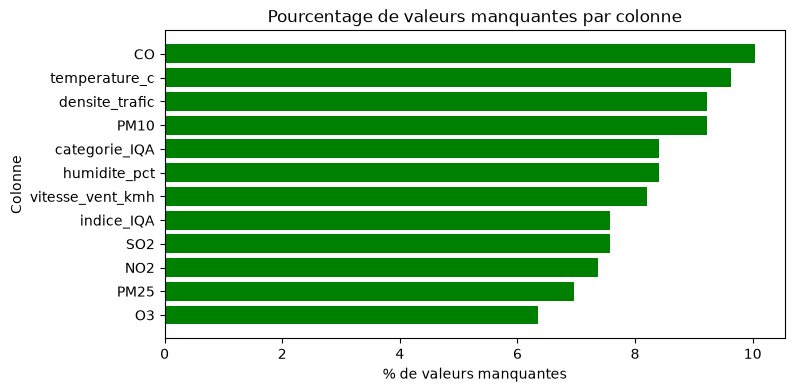

In [44]:
# Pourcentage de valeurs manquantes par colonne
manquant = df.isna().mean() * 100

# mask pour déterminer les valeurs manquantes
manquant = manquant[manquant > 0].sort_values()

fig, ax = plt.subplots(figsize=(8, 4))
ax.barh(manquant.index, manquant.values, color="GREEN")

# Afficher le diagramme
ax.set_title("Pourcentage de valeurs manquantes par colonne")
ax.set_xlabel("% de valeurs manquantes")
ax.set_ylabel("Colonne")
plt.show()


## Identifiez les colonnes les plus affectées.
Par ordre décroissant, les plus affectées sont:
* CO
* temperature_c
* densite_trafic
* pm10
* ...

# Identifiez et affichez les lignes dupliquées. Combien y en a-t-il ? Quelle proportion représentent-elles ?


In [48]:
# Toutes les lignes identiques
masque = df.duplicated(keep=False) 
df[masque]

,id_station,ville,region,type_zone,PM25,PM10,NO2,O3,CO,SO2,temperature_c,humidite_pct,vitesse_vent_kmh,densite_trafic,annee,indice_IQA,categorie_IQA
4,138,Lyon,Auvergne-Rhône-Alpes,Rural,16.0,32.1,1.0,40.2,0.17,0.1,16.5,70.8,23.9,19700.0,2024,42.3,Bon
16,184,Nice,Provence-Alpes-Côte d'Azur,Périurbain,7.6,NaN,16.7,70.4,1.18,7.1,10.4,75.9,11.2,5935.0,2018,94.6,Moyen
17,395,Marseille,Provence-Alpes-Côte d'Azur,Urbain,NaN,56.6,30.4,56.3,0.13,0.1,14.2,62.0,NaN,32892.0,2020,111.7,Dégradé
21,173,Paris,Île-de-France,Périurbain,6.7,10.9,5.5,83.5,1.09,1.5,18.9,30.7,41.7,17710.0,2023,62.4,Moyen
98,173,Paris,Île-de-France,Périurbain,6.7,10.9,5.5,83.5,1.09,1.5,18.9,30.7,41.7,17710.0,2023,62.4,Moyen
101,217,Nantes,Pays de la Loire,Périurbain,13.2,24.2,42.6,102.1,0.75,0.1,NaN,73.7,3.4,20384.0,2022,131.2,Dégradé
119,175,Strasbourg,Grand Est,Périurbain,12.4,34.4,25.8,41.7,0.95,1.7,20.3,34.2,8.0,10469.0,2022,74.4,Moyen
166,175,Strasbourg,Grand Est,Périurbain,12.4,34.4,25.8,41.7,0.95,1.7,20.3,34.2,8.0,10469.0,2022,74.4,Moyen
206,57,Lyon,Auvergne-Rhône-Alpes,Urbain,2.9,9.7,22.1,41.6,1.02,19.6,18.1,77.3,5.3,915.0,2018,58.0,Moyen
225,57,Lyon,Auvergne-Rhône-Alpes,Urbain,2.9,9.7,22.1,41.6,1.02,19.6,18.1,77.3,5.3,915.0,2018,58.0,Moyen


In [54]:
nb_dup = df.duplicated().sum()
print(f"Lignes dupliquées (celles que l'on va devoirsupprimer) : {nb_dup}")

Lignes dupliquées (copies à supprimer) : 8


In [61]:
proportion_dup = (nb_dup / len(df) * 100)
print(f"Proportion : {proportion_dup} % du jeu de données")

Proportion : 1.639344262295082 % du jeu de données


# Partie 2 - Nettoyage de données

In [120]:
# Avant nettoyage
nb_lignes_avant_net = len(df)
print(f"Le nombre de lignes avant le nettoyage des dupliquées {nb_lignes_avant_net}")



Le nombre de lignes avant le nettoyage des dupliquées 488


In [121]:
cleaned_df = df.drop_duplicates(keep="first").reset_index(drop=True)

In [122]:
# Avant nettoyage
nb_lignes_apres_net = len(cleaned_df)
print(f"Le nombre de lignes avant le nettoyage des dupliquées {nb_lignes_apres_net}")



Le nombre de lignes avant le nettoyage des dupliquées 487


In [123]:
# Afficher le dataframe nettoyé (sans duplication de ligne)
cleaned_df

,id_station,ville,region,type_zone,PM25,PM10,NO2,O3,CO,SO2,temperature_c,humidite_pct,vitesse_vent_kmh,densite_trafic,annee,indice_IQA,categorie_IQA
0,438,Toulouse,Occitanie,Périurbain,20.7,52.1,8.2,35.2,0.36,5.7,19.2,44.0,14.3,52277.0,2024,92.0,Moyen
1,369,Paris,Île-de-France,Périurbain,3.2,12.8,52.7,41.0,1.00,8.8,7.8,60.1,32.6,4469.0,2021,84.8,Moyen
2,340,Lille,Hauts-de-France,Urbain,12.7,24.4,10.2,21.7,0.64,2.3,24.0,70.6,2.9,36643.0,2020,45.9,NaN
3,281,Rennes,Bretagne,Rural,NaN,27.3,22.3,NaN,0.35,3.0,5.5,42.6,20.8,14651.0,2020,49.4,??
4,138,Lyon,Auvergne-Rhône-Alpes,Rural,16.0,32.1,1.0,40.2,0.17,0.1,16.5,70.8,23.9,19700.0,2024,42.3,Bon
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
482,202,Marseille,Provence-Alpes-Côte d'Azur,NaN,4.9,2.0,23.5,77.8,NaN,0.3,14.8,66.4,4.8,8941.0,2021,100.1,NaN
483,169,Bordeaux,Nouvelle-Aquitaine,NaN,28.7,48.5,950.0,75.4,0.10,2.9,25.2,71.0,5.7,26886.0,2021,NaN,Dégradé
484,186,Nice,Provence-Alpes-Côte d'Azur,NaN,12.5,14.2,24.3,47.2,1.51,4.6,13.1,61.4,13.4,32598.0,2022,92.7,Moyen
485,36,Nice,Provence-Alpes-Côte d'Azur,NaN,11.6,18.7,6.9,69.6,1.36,11.1,33.9,27.6,24.4,27205.0,2019,107.4,Dégradé


### Plusieurs colonnes contiennent des erreurs de casse, des espaces parasites ou des valeurs incohérentes. Identifiez-les et normalisez-les :

In [124]:
# VILLE
cleaned_df["ville"] = (cleaned_df["ville"].str.strip().str.rstrip(".").str.title())
print("Les noms des villes normalisées :", sorted(cleaned_df["ville"].unique()))

Les noms des villes normalisées : ['Bordeaux', 'Lille', 'Lyon', 'Marseille', 'Nantes', 'Nice', 'Paris', 'Rennes', 'Strasbourg', 'Toulouse']


In [125]:
# TYPE_ZONE
# Identifier les différentes manières dont sont écrits les valeurs dans la colonne
print("Colonne: ", cleaned_df["type_zone"].value_counts())

Colonne:  type_zone
Urbain        191
Périurbain    140
Rural          87
Industriel     61
Name: count, dtype: int64


In [126]:
# Dictionnaire de mapping
map_zone = {"urbain": "Urbain", "périurbain": "Périurbain", "periurbain": "Périurbain",
            "rural": "Rural", "industriel": "Industriel"}

cleaned_df["type_zone"] = cleaned_df["type_zone"].str.strip().str.lower().replace(map_zone)
print("Après :", cleaned_df["type_zone"].value_counts())

Après : type_zone
Urbain        191
Périurbain    140
Rural          87
Industriel     61
Name: count, dtype: int64


In [127]:
# CATEGORIE IQA
print("Avant :", cleaned_df["categorie_IQA"].value_counts(dropna=False))

Avant : categorie_IQA
Moyen           186
Dégradé         156
Mauvais          45
NaN              41
Bon              33
Très mauvais     16
??                1
MOYEN             1
Acceptable        1
BON               1
Excellent         1
NC                1
tres mauvais      1
dégradé           1
Mauvai            1
bon               1
Name: count, dtype: int64


In [128]:
# Même procédé par mapping 
CATEGORIES_VALIDES = ["Bon", "Moyen", "Dégradé", "Mauvais", "Très mauvais"]
map_cat = {"bon": "Bon", "moyen": "Moyen",
           "dégradé": "Dégradé", "degrade": "Dégradé",
           "mauvais": "Mauvais", "mauvai": "Mauvais",
           "très mauvais": "Très mauvais", "tres mauvais": "Très mauvais"}
cleaned_df["categorie_IQA"] = df["categorie_IQA"].str.strip().str.lower().replace(map_cat)

# Normalisation
print("Après :", cleaned_df["categorie_IQA"].value_counts(dropna=False))
print("Lignes restantes :", len(cleaned_df))

Après : categorie_IQA
Moyen           187
Dégradé         157
Mauvais          46
NaN              41
Bon              35
Très mauvais     17
??                1
acceptable        1
excellent         1
nc                1
Name: count, dtype: int64
Lignes restantes : 487


#### Remarque
Nous avons décidé de supprimer (comme conseillé) toutes les valeurs hors de celles requises par l'exercice.
**HORS : Bon, Moyen, Dégradé, Mauvais, Très mauvais**

In [129]:
masque = cleaned_df["categorie_IQA"] != "??"
cleaned_df = cleaned_df[masque]

# affichage des valeurs
print("Après la première suppression :", cleaned_df["categorie_IQA"].value_counts(dropna=False))

Après la première suppression : categorie_IQA
Moyen           187
Dégradé         157
Mauvais          46
NaN              41
Bon              35
Très mauvais     17
acceptable        1
excellent         1
nc                1
Name: count, dtype: int64


In [130]:
masque = cleaned_df["categorie_IQA"] != "acceptable"
cleaned_df = cleaned_df[masque]

# affichage des valeurs
print("Après la seconde suppression :", cleaned_df["categorie_IQA"].value_counts(dropna=False))

Après la première suppression : categorie_IQA
Moyen           187
Dégradé         157
Mauvais          46
NaN              41
Bon              35
Très mauvais     17
excellent         1
nc                1
Name: count, dtype: int64


In [131]:
masque = cleaned_df["categorie_IQA"] != "excellent"
cleaned_df = cleaned_df[masque]

# affichage des valeurs
print("Après la troisième suppression :", cleaned_df["categorie_IQA"].value_counts(dropna=False))

Après la seconde suppression : categorie_IQA
Moyen           187
Dégradé         157
Mauvais          46
NaN              41
Bon              35
Très mauvais     17
nc                1
Name: count, dtype: int64


In [133]:
masque = cleaned_df["categorie_IQA"] != "nc"
cleaned_df = cleaned_df[masque]

# affichage des valeurs
print("Après la quatrième suppression :", cleaned_df["categorie_IQA"].value_counts(dropna=False))

Après la quatrième suppression : categorie_IQA
Moyen           187
Dégradé         157
Mauvais          46
NaN              41
Bon              35
Très mauvais     17
Name: count, dtype: int64


In [135]:
# Supprimer les NaN
cleaned_df = cleaned_df.dropna(subset=["categorie_IQA"])

print("Après la quatrième suppression :", cleaned_df["categorie_IQA"].value_counts(dropna=False))


Après la quatrième suppression : categorie_IQA
Moyen           187
Dégradé         157
Mauvais          46
Bon              35
Très mauvais     17
Name: count, dtype: int64


### Traitement des valeurs aberrantes

In [136]:
# Affichage du DF
cleaned_df

,id_station,ville,region,type_zone,PM25,PM10,NO2,O3,CO,SO2,temperature_c,humidite_pct,vitesse_vent_kmh,densite_trafic,annee,indice_IQA,categorie_IQA
0,438,Toulouse,Occitanie,Périurbain,20.7,52.1,8.2,35.2,0.36,5.7,19.2,44.0,14.3,52277.0,2024,92.0,Moyen
1,369,Paris,Île-de-France,Périurbain,3.2,12.8,52.7,41.0,1.00,8.8,7.8,60.1,32.6,4469.0,2021,84.8,Moyen
4,138,Lyon,Auvergne-Rhône-Alpes,Rural,16.0,32.1,1.0,40.2,0.17,0.1,16.5,70.8,23.9,19700.0,2024,42.3,Bon
6,172,Nantes,Pays de la Loire,Rural,9.5,19.4,1.2,75.3,0.90,0.4,13.8,NaN,29.3,3642.0,2022,NaN,Moyen
7,200,Rennes,Bretagne,Industriel,24.1,51.5,19.0,46.9,1.02,4.5,15.6,47.9,25.0,4141.0,2022,129.2,Dégradé
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
481,233,Lille,Hauts-de-France,NaN,10.8,24.0,1.0,51.6,0.10,13.6,13.2,75.1,28.7,NaN,2018,NaN,Moyen
482,202,Marseille,Provence-Alpes-Côte d'Azur,NaN,4.9,2.0,23.5,77.8,NaN,0.3,14.8,66.4,4.8,8941.0,2021,100.1,Moyen
484,186,Nice,Provence-Alpes-Côte d'Azur,NaN,12.5,14.2,24.3,47.2,1.51,4.6,13.1,61.4,13.4,32598.0,2022,92.7,Dégradé
485,36,Nice,Provence-Alpes-Côte d'Azur,NaN,11.6,18.7,6.9,69.6,1.36,11.1,33.9,27.6,24.4,27205.0,2019,107.4,Moyen


In [143]:
masque_pm25 = cleaned_df["PM25"] < 0
masque_pm10 = cleaned_df["PM10"] < 0
masque_nO2 = cleaned_df["NO2"] > 500
masque_temperature_c = (cleaned_df["temperature_c"] < -50) | (cleaned_df["temperature_c"] > 60)
masque_annee = (cleaned_df["annee"] < 2010) | (cleaned_df["annee"] > 2024)

tous_les_masques = {
    "PM25": masque_pm25,
    "PM10": masque_pm10,
    "NO2": masque_nO2,
    "temperature_c": masque_temperature_c,
    "annee": masque_annee,
}

resultat = []
for col, masque in tous_les_masques.items():
    valeurs = cleaned_df.loc[masque, col].tolist()
    resultat.append({"colonne": col, "nb_impossibles": int(masque.sum()), "valeurs": valeurs})
    cleaned_df.loc[masque, col] = np.nan

pd.DataFrame(resultat)


,colonne,nb_impossibles,valeurs
0,PM25,4,"[-8.8, -18.6, -18.2, -24.8]"
1,PM10,0,[]
2,NO2,1,[950.0]
3,temperature_c,1,[-62.5]
4,annee,2,"[2029, 2030]"


*Interprétation*

Il y avait énormément de valeurs aberrantes, le nettoyage et a été utile car il n'y avait que la colonne PM10 qui ne comportait pas de valeurs impossibles.

In [144]:
# Affichage du df
cleaned_df

,id_station,ville,region,type_zone,PM25,PM10,NO2,O3,CO,SO2,temperature_c,humidite_pct,vitesse_vent_kmh,densite_trafic,annee,indice_IQA,categorie_IQA
0,438,Toulouse,Occitanie,Périurbain,20.7,52.1,8.2,35.2,0.36,5.7,19.2,44.0,14.3,52277.0,2024.0,92.0,Moyen
1,369,Paris,Île-de-France,Périurbain,3.2,12.8,52.7,41.0,1.00,8.8,7.8,60.1,32.6,4469.0,2021.0,84.8,Moyen
4,138,Lyon,Auvergne-Rhône-Alpes,Rural,16.0,32.1,1.0,40.2,0.17,0.1,16.5,70.8,23.9,19700.0,2024.0,42.3,Bon
6,172,Nantes,Pays de la Loire,Rural,9.5,19.4,1.2,75.3,0.90,0.4,13.8,NaN,29.3,3642.0,2022.0,NaN,Moyen
7,200,Rennes,Bretagne,Industriel,24.1,51.5,19.0,46.9,1.02,4.5,15.6,47.9,25.0,4141.0,2022.0,129.2,Dégradé
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
481,233,Lille,Hauts-de-France,NaN,10.8,24.0,1.0,51.6,0.10,13.6,13.2,75.1,28.7,NaN,2018.0,NaN,Moyen
482,202,Marseille,Provence-Alpes-Côte d'Azur,NaN,4.9,2.0,23.5,77.8,NaN,0.3,14.8,66.4,4.8,8941.0,2021.0,100.1,Moyen
484,186,Nice,Provence-Alpes-Côte d'Azur,NaN,12.5,14.2,24.3,47.2,1.51,4.6,13.1,61.4,13.4,32598.0,2022.0,92.7,Dégradé
485,36,Nice,Provence-Alpes-Côte d'Azur,NaN,11.6,18.7,6.9,69.6,1.36,11.1,33.9,27.6,24.4,27205.0,2019.0,107.4,Moyen


### Méthode IQR
Nous n'avons pas implémenté la méthode IQR car après avoir vérifié avec vous comme nous ne l'avons pas traité en cours.

### Imputation des valeurs manquantes

Choix appliqués :
1. les lignes sans IQA sont **supprimées** (pas d'imputation de la variable à prédire).
2. **médiane** si la distribution est asymétrique.
3. médiane arrondie (variable entière discrète).


In [146]:
# 1) Suppression des lignes sans variable cible
n_avant = len(cleaned_df)
cleaned_df = cleaned_df.dropna(subset=["indice_IQA"]).reset_index(drop=True)
print(f"Lignes sans indice_IQA supprimées : {n_avant - len(cleaned_df)} | lignes restantes : {len(cleaned_df)}")

Lignes sans indice_IQA supprimées : 32 | lignes restantes : 410


In [149]:
# 2) Variables numériques continues : remplacer les NaN par la médiane ou la moyenne
#    - Si la distribution est asymétrique (|skewness| > 0.5), on utilise la médiane
#    - Sinon, la distribution est à peu près symétrique et on utilise la moyenne.

# Toutes les colonnes numériques sauf indice_IQA
COLS_NUM = ["PM25", "PM10", "NO2", "O3", "CO", "SO2",
            "temperature_c", "humidite_pct", "vitesse_vent_kmh",
            "densite_trafic", "indice_IQA"]

colonnes_a_imputer = []
for colonne in COLS_NUM:
    if colonne != "indice_IQA":
        colonnes_a_imputer.append(colonne)

tableau_des_choix = []

for colonne in colonnes_a_imputer:
    # Mesurer l'asymétrie de la distribution
    asymetrie = df[colonne].skew()

    # Choix de la valeur de remplacement
    if abs(asymetrie) > 0.5:
        methode = "médiane"
        valeur_de_remplacement = df[colonne].median()
    else:
        methode = "moyenne"
        valeur_de_remplacement = df[colonne].mean()

    # Nombre de NaN avant remplacement
    nb_valeurs_manquantes = df[colonne].isna().sum()

    # Remplacement des NaN
    cleaned_df[colonne] = cleaned_df[colonne].fillna(valeur_de_remplacement)

    # Tous les changements faits
    tableau_des_choix.append({
        "variable": colonne,
        "nb_NaN_imputés": int(nb_valeurs_manquantes),
        "asymétrie (skewness)": round(asymetrie, 2),
        "méthode": methode,
        "valeur_imputée": round(valeur_de_remplacement, 2),
    })

# Affichage du récapitulatif
pd.DataFrame(tableau_des_choix).set_index("variable")


,nb_NaN_imputés,asymétrie (skewness),méthode,valeur_imputée
variable,,,,
PM25,37,1.07,médiane,15.80
PM10,45,1.17,médiane,31.00
NO2,33,2.17,médiane,21.20
O3,29,0.02,moyenne,57.87
CO,45,1.75,médiane,0.57
SO2,33,2.10,médiane,4.40
temperature_c,45,-0.02,moyenne,14.07
humidite_pct,36,-0.11,moyenne,66.53
vitesse_vent_kmh,36,1.14,médiane,13.40


* Médiane (7 variables : PM25, PM10, NO2, CO, SO2, vitesse_vent_kmh, densite_trafic), la médiane est plus représentative.
* Moyenne (3 variables : O3, temperature_c, humidite_pct) : la skewness est proche de 0, donc la distribution est symétrique et la moyenne convient.
* Volume : entre 29 et 45 NaN supprimés par variable. Cela comprend les valeurs impossibles remplacées par NaN juste avant.

In [150]:
# Afficher le dataframe nettoyé
cleaned_df

,id_station,ville,region,type_zone,PM25,PM10,NO2,O3,CO,SO2,temperature_c,humidite_pct,vitesse_vent_kmh,densite_trafic,annee,indice_IQA,categorie_IQA
0,438,Toulouse,Occitanie,Périurbain,20.7,52.1,8.2,35.2,0.36,5.7,19.2,44.0,14.3,52277.0,2024.0,92.0,Moyen
1,369,Paris,Île-de-France,Périurbain,3.2,12.8,52.7,41.0,1.00,8.8,7.8,60.1,32.6,4469.0,2021.0,84.8,Moyen
2,138,Lyon,Auvergne-Rhône-Alpes,Rural,16.0,32.1,1.0,40.2,0.17,0.1,16.5,70.8,23.9,19700.0,2024.0,42.3,Bon
3,200,Rennes,Bretagne,Industriel,24.1,51.5,19.0,46.9,1.02,4.5,15.6,47.9,25.0,4141.0,2022.0,129.2,Dégradé
4,203,Paris,Hauts-de-France,Périurbain,18.2,31.0,44.7,68.7,0.20,3.2,12.6,91.4,16.5,13219.0,2023.0,104.3,Dégradé
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
405,211,Strasbourg,Grand Est,NaN,2.9,11.2,24.6,110.4,0.15,0.3,6.5,56.1,45.8,20823.0,2022.0,84.6,Bon
406,202,Marseille,Provence-Alpes-Côte d'Azur,NaN,4.9,2.0,23.5,77.8,0.57,0.3,14.8,66.4,4.8,8941.0,2021.0,100.1,Moyen
407,186,Nice,Provence-Alpes-Côte d'Azur,NaN,12.5,14.2,24.3,47.2,1.51,4.6,13.1,61.4,13.4,32598.0,2022.0,92.7,Dégradé
408,36,Nice,Provence-Alpes-Côte d'Azur,NaN,11.6,18.7,6.9,69.6,1.36,11.1,33.9,27.6,24.4,27205.0,2019.0,107.4,Moyen


**Bilan**

Il ne reste aucune valeur manquante ni aucun doublon, et toutes les plages de valeurs sont physiquement possibles.


# Partie 3

### Analyse univariée


#### IQA

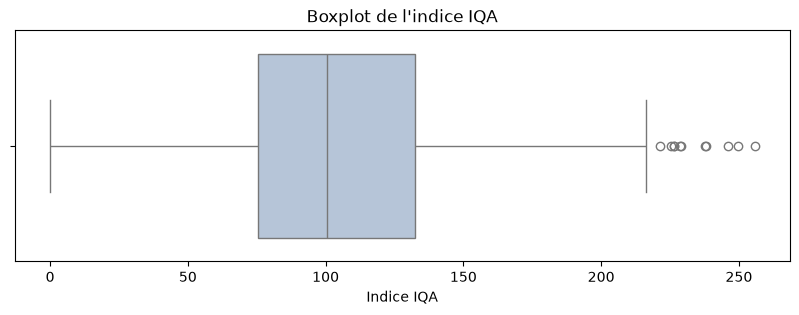

count    410.000000
mean     106.843659
std       45.204456
min        0.000000
25%       75.575000
50%      100.400000
75%      132.350000
max      255.700000
Name: indice_IQA, dtype: float64


In [161]:
fig, ax = plt.subplots(figsize=(10, 3))
sns.boxplot(x=cleaned_df["indice_IQA"], ax=ax, color="lightsteelblue")
ax.set_title("Boxplot de l'indice IQA")
ax.set_xlabel("Indice IQA")
plt.show()

print(cleaned_df["indice_IQA"].describe())


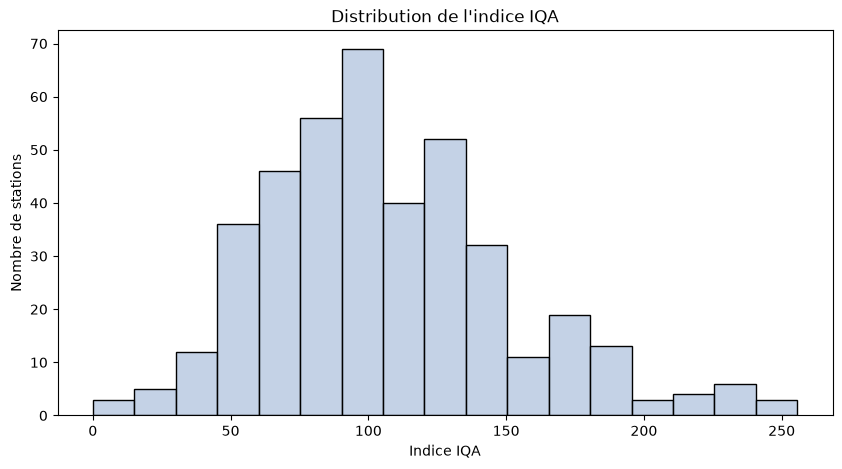

In [172]:
fig, ax = plt.subplots(figsize=(10, 5))
sns.histplot(cleaned_df["indice_IQA"], ax=ax, color="lightsteelblue")
ax.set_title("Distribution de l'indice IQA")
ax.set_xlabel("Indice IQA")
ax.set_ylabel("Nombre de stations")
plt.show()


**Interprétation**
* la médiane est à 100.4. Une station sur deux a un IQA inférieur à environ 101.
* Dispersion : la boîte va de environ 76  à 132.9 , donc la moitié des stations se trouve entre ces deux valeurs. L'écart est large : la qualité de l'air varie beaucoup d'une station à l'autre.
* Pic : la classe la plus fréquente est 90–105, avec 69 stations. C'est cohérent avec la médiane à 100.4.
* Concentration : la majorité des stations se trouve entre 45 et 150.

#### PM 25

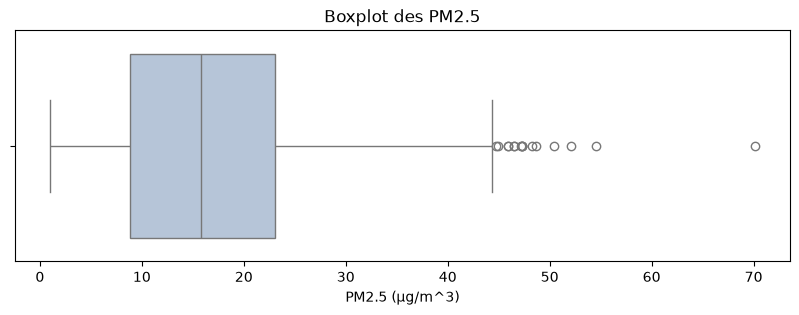

count    410.000000
mean      17.417073
std       11.449135
min        1.000000
25%        8.800000
50%       15.800000
75%       23.075000
max       70.100000
Name: PM25, dtype: float64


In [174]:
fig, ax = plt.subplots(figsize=(10, 3))
sns.boxplot(x=cleaned_df["PM25"], ax=ax, color="lightsteelblue")
ax.set_title("Boxplot des PM2.5")
ax.set_xlabel("PM2.5 (µg/m^3)")
plt.show()

print(cleaned_df["PM25"].describe())


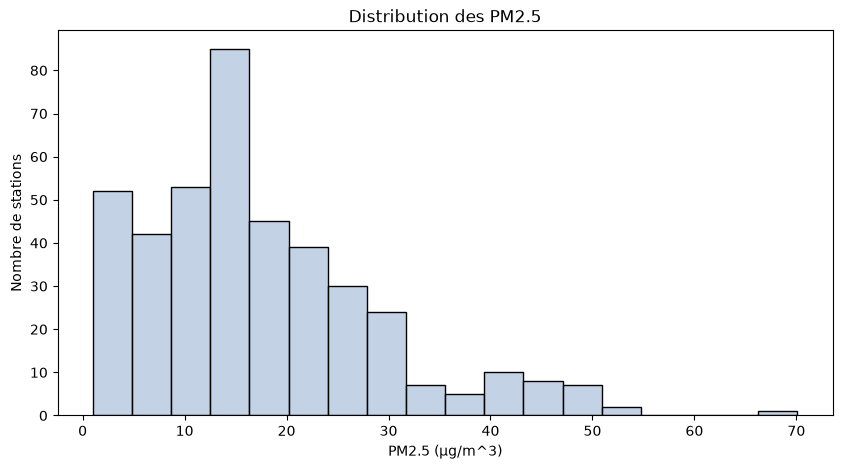

In [176]:
fig, ax = plt.subplots(figsize=(10, 5))
sns.histplot(cleaned_df["PM25"], ax=ax, color="lightsteelblue")
ax.set_title("Distribution des PM2.5")
ax.set_xlabel("PM2.5 (µg/m^3)")
ax.set_ylabel("Nombre de stations")
plt.show()


**Interprétation**
* la médiane est d'environ 15.8 µg/m^3, et la moitié des stations se trouve entre 8.8 et 23.5 µg/m^3.
* la moyenne (environ 17.5) est au-dessus de la médiane, et la queue s'étire jusqu'à environ 70 µg/m^3.
* environ 15 stations dépassent la borne haute (environ 45 µg/m^3).

#### N02

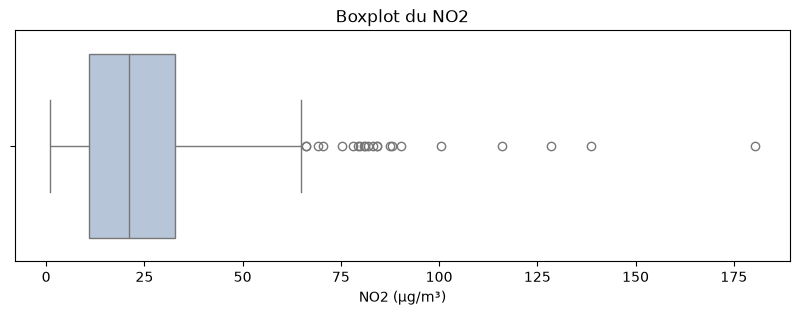

count    410.000000
mean      25.767805
std       21.977086
min        1.000000
25%       11.025000
50%       21.200000
75%       32.775000
max      180.300000
Name: NO2, dtype: float64


In [177]:
fig, ax = plt.subplots(figsize=(10, 3))
sns.boxplot(x=cleaned_df["NO2"], ax=ax, color="lightsteelblue")
ax.set_title("Boxplot du NO2")
ax.set_xlabel("NO2 (µg/m³)")
plt.show()

print(cleaned_df["NO2"].describe())


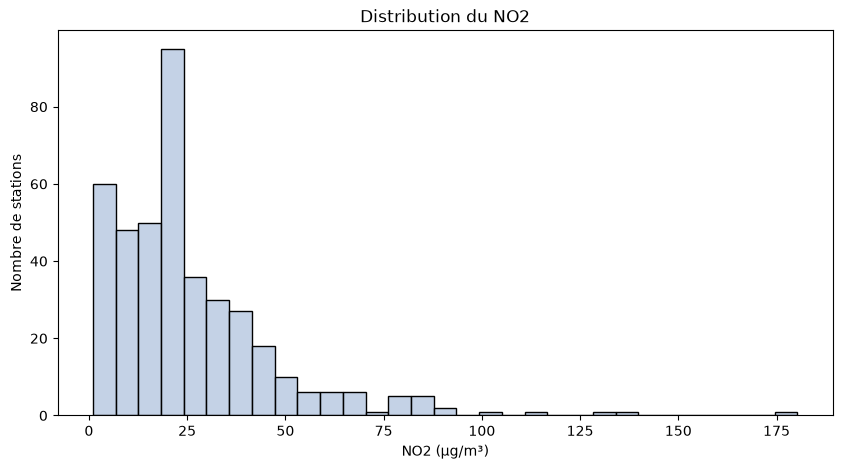

In [178]:
fig, ax = plt.subplots(figsize=(10, 5))
sns.histplot(cleaned_df["NO2"], ax=ax, color="lightsteelblue")
ax.set_title("Distribution du NO2")
ax.set_xlabel("NO2 (µg/m³)")
ax.set_ylabel("Nombre de stations")
plt.show()


**Interprétation**
* la médiane est de 21 µg/m^3, et environ la moitié des stations se trouve entre 11.5 et 30 µg/m^3.
* la moyenne (environ 26) est au-dessus de la médiane, et la queue va jusqu'à 180 µg/m^3. 
* environ 20 stations dépassent la borne haute (d'environ 65 µg/m^3).

### Corrélation

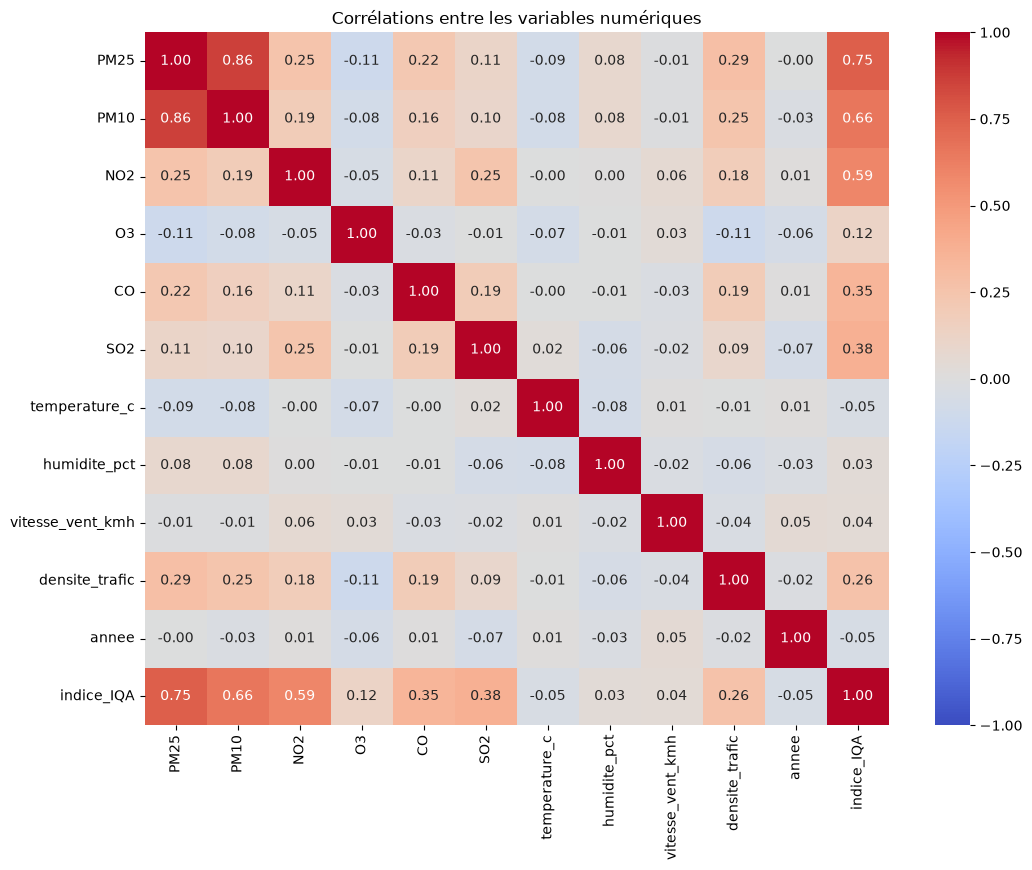

indice_IQA          1.000000
PM25                0.752403
PM10                0.661527
NO2                 0.592107
SO2                 0.378707
CO                  0.346372
densite_trafic      0.258235
O3                  0.122800
vitesse_vent_kmh    0.041200
humidite_pct        0.034060
temperature_c      -0.046087
annee              -0.050627
Name: indice_IQA, dtype: float64


In [180]:
colonnes = ["PM25", "PM10", "NO2", "O3", "CO", "SO2",
            "temperature_c", "humidite_pct", "vitesse_vent_kmh",
            "densite_trafic", "annee", "indice_IQA"]

correlations = cleaned_df[colonnes].corr()

# Heatmap
fig, ax = plt.subplots(figsize=(12, 9))
sns.heatmap(correlations, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, ax=ax)
ax.set_title("Corrélations entre les variables numériques")
plt.show()

print(correlations["indice_IQA"].sort_values(ascending=False))


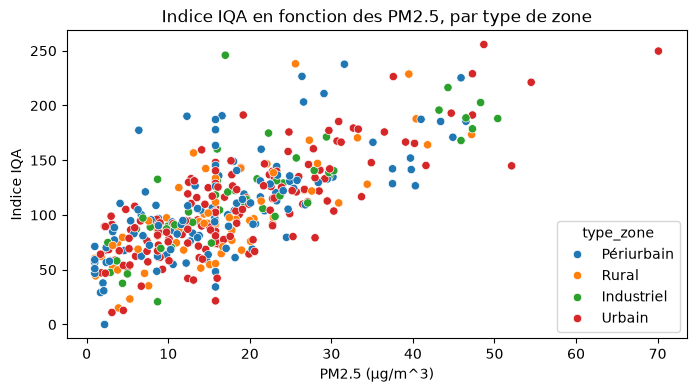

In [185]:
fig, ax = plt.subplots(figsize=(8, 4))
sns.scatterplot(data=cleaned_df, x="PM25", y="indice_IQA", hue="type_zone", ax=ax)
ax.set_title("Indice IQA en fonction des PM2.5, par type de zone")
ax.set_xlabel("PM2.5 (µg/m^3)")
ax.set_ylabel("Indice IQA")
plt.show()


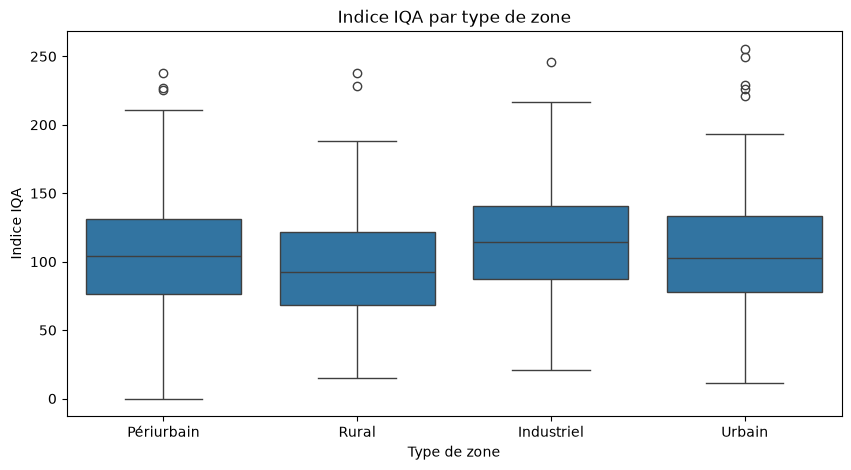

In [186]:
fig, ax = plt.subplots(figsize=(10, 5))
sns.boxplot(data=cleaned_df, x="type_zone", y="indice_IQA", ax=ax)
ax.set_title("Indice IQA par type de zone")
ax.set_xlabel("Type de zone")
ax.set_ylabel("Indice IQA")
plt.show()


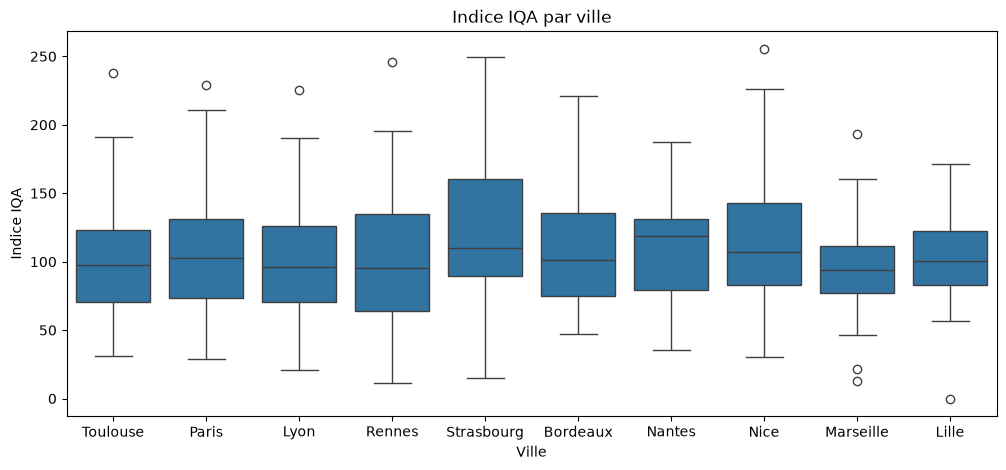

In [187]:
fig, ax = plt.subplots(figsize=(12, 5))
sns.boxplot(data=cleaned_df, x="ville", y="indice_IQA", ax=ax)
ax.set_title("Indice IQA par ville")
ax.set_xlabel("Ville")
ax.set_ylabel("Indice IQA")
plt.show()


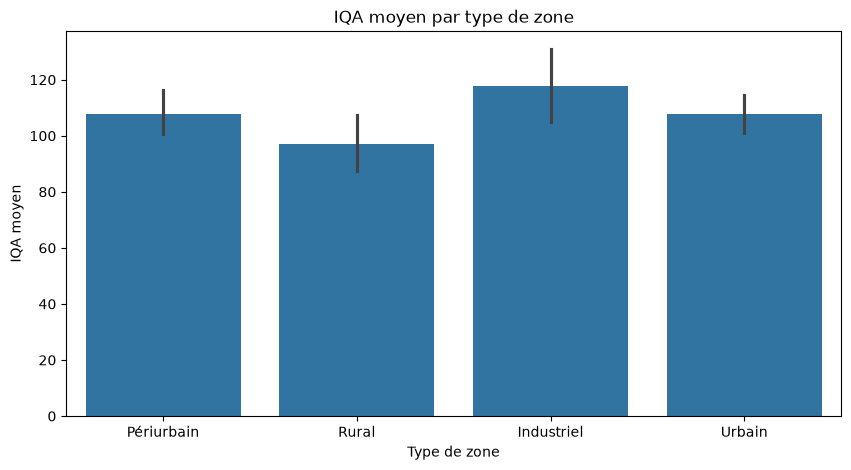

In [188]:
fig, ax = plt.subplots(figsize=(10, 5))
sns.barplot(data=cleaned_df, x="type_zone", y="indice_IQA", ax=ax)
ax.set_title("IQA moyen par type de zone")
ax.set_xlabel("Type de zone")
ax.set_ylabel("IQA moyen")
plt.show()


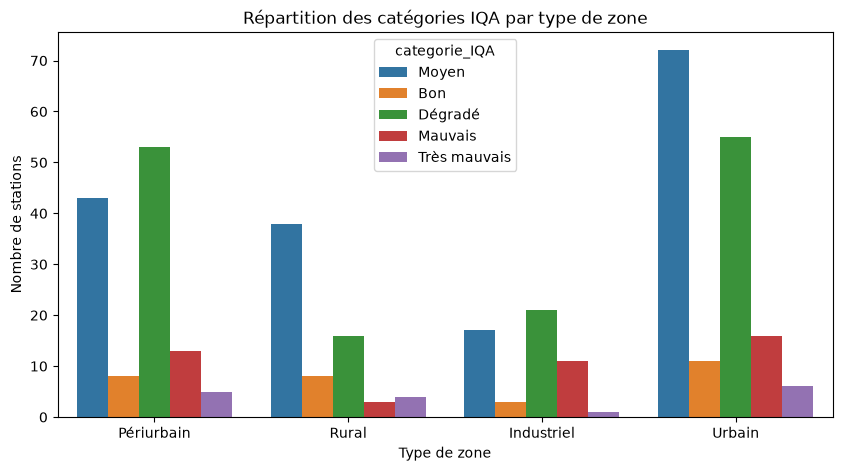

In [189]:
fig, ax = plt.subplots(figsize=(10, 5))
sns.countplot(data=cleaned_df, x="type_zone", hue="categorie_IQA", ax=ax)
ax.set_title("Répartition des catégories IQA par type de zone")
ax.set_xlabel("Type de zone")
ax.set_ylabel("Nombre de stations")
plt.show()


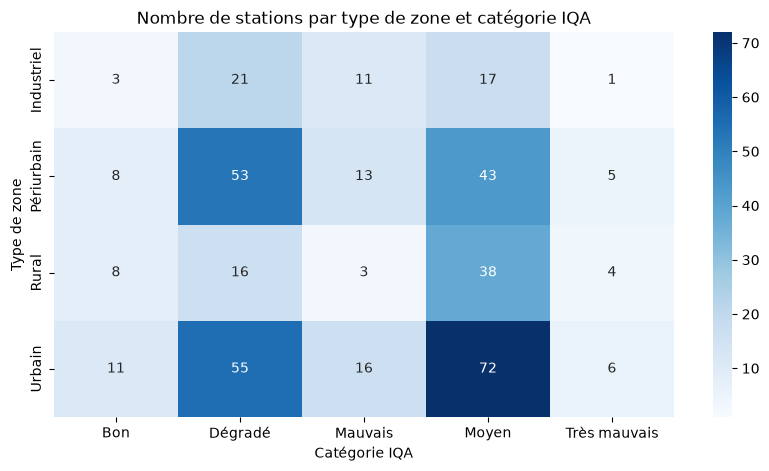

In [190]:
tableau = pd.crosstab(cleaned_df["type_zone"], cleaned_df["categorie_IQA"])

fig, ax = plt.subplots(figsize=(10, 5))
sns.heatmap(tableau, annot=True, fmt="d", cmap="Blues", ax=ax)
ax.set_title("Nombre de stations par type de zone et catégorie IQA")
ax.set_xlabel("Catégorie IQA")
ax.set_ylabel("Type de zone")
plt.show()


count    410.000000
mean       2.354495
std        1.849608
min        0.289855
25%        1.653575
50%        2.006250
75%        2.464554
max       17.222222
Name: ratio_PM, dtype: float64


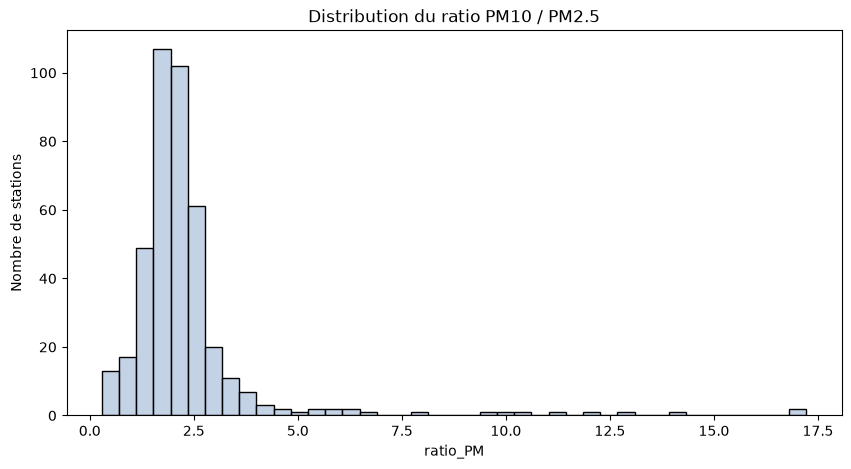

In [194]:
# Rapport de granulométrie 
cleaned_df["ratio_PM"] = cleaned_df["PM10"] / cleaned_df["PM25"]

print(cleaned_df["ratio_PM"].describe())

fig, ax = plt.subplots(figsize=(10, 5))
sns.histplot(cleaned_df["ratio_PM"], ax=ax, color="lightsteelblue")
ax.set_title("Distribution du ratio PM10 / PM2.5")
ax.set_xlabel("ratio_PM")
ax.set_ylabel("Nombre de stations")
plt.show()


* Ratio proche de 1 à 1.5 : surtout des particules fines (les plus nombreux).
* Ratio supérieur à 2 : beaucoup de grosses particules (le pic des valeurs).

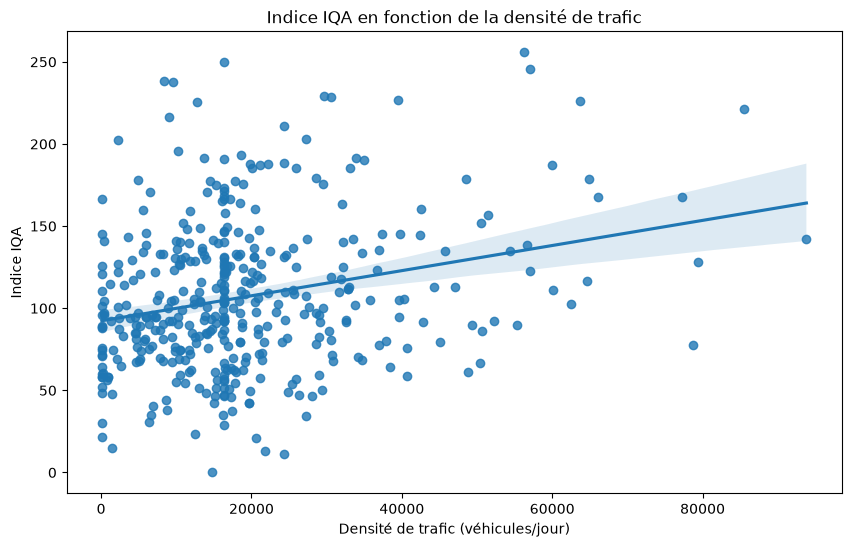

In [197]:
fig, ax = plt.subplots(figsize=(10, 6))
sns.regplot(data=cleaned_df, x="densite_trafic", y="indice_IQA", ax=ax)
ax.set_title("Indice IQA en fonction de la densité de trafic")
ax.set_xlabel("Densité de trafic (véhicules/jour)")
ax.set_ylabel("Indice IQA")
plt.show()


**Interprétation**
* Forte dispersion : l'IQA varie beaucoup. Il va d'environ 10 à 250. 
* Colonne verticale vers 16 500 : ce sont les 40 valeurs de densite_trafic imputées par la médiane.
* Peu de données au-delà de 40 000 : la zone d'incertitude s'élargit à partir de ce niveau.

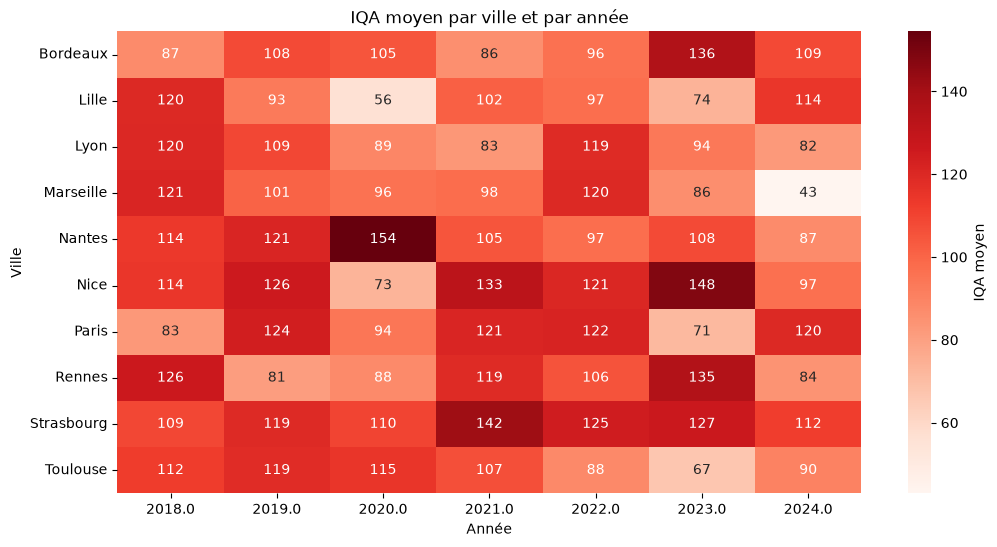

In [198]:
pivot = cleaned_df.pivot_table(index="ville", columns="annee", values="indice_IQA", aggfunc="mean")

fig, ax = plt.subplots(figsize=(12, 6))
sns.heatmap(pivot, annot=True, fmt=".0f", cmap="Reds", ax=ax,cbar_kws={"label": "IQA moyen"})
ax.set_title("IQA moyen par ville et par année")
ax.set_xlabel("Année")
ax.set_ylabel("Ville")
plt.show()


**Interprétation**
* Villes : Strasbourg est la plus régulièrement polluée. Toutes ses années sont à 109 ou plus, pour une moyenne d'environ 121.
* Moyennes remarquables : Lille (environ 94), Marseille (environ 95) sont les plus basses en moyenne sur cette période de temps.
* Années : la moyenne tourne autour de 110 de 2018 à 2022, puis baisse en 2023 (environ 105) et en 2024 (environ 94).

# Partie 4

* Hypothèse 1 : l'IQA diffère selon le type de zone
* Hypothèse 2 : plus le trafic est dense, plus le NO2 est élevé
* Hypothèse 3 : le vent fait baisser les PM2.5

In [200]:
# Hypothèse 1
print(cleaned_df.groupby("type_zone")["indice_IQA"].mean().round(1))

# Une série d'IQA par zone
urbain = cleaned_df[cleaned_df["type_zone"] == "Urbain"]["indice_IQA"]
periurbain = cleaned_df[cleaned_df["type_zone"] == "Périurbain"]["indice_IQA"]
rural = cleaned_df[cleaned_df["type_zone"] == "Rural"]["indice_IQA"]
industriel = cleaned_df[cleaned_df["type_zone"] == "Industriel"]["indice_IQA"]

# ANOVA
f, p = stats.f_oneway(urbain, periurbain, rural, industriel)
print(f"F = {f:.2f}, p-value = {p:.4f}")


type_zone
Industriel    117.8
Périurbain    107.9
Rural          97.0
Urbain        107.7
Name: indice_IQA, dtype: float64
F = 2.17, p-value = 0.0909


**Interprétation**

La p-value est proche du seuil de 10%: Donc  le résultat n'est pas assez significatif.

Observation : le boxplot et le barplot de l'IQA par type_zone montrent un IQA moyen plus élevé en zone Industrielle et plus bas en zone Rurale.


In [203]:
# Hypthèse 2
rho, p = stats.spearmanr(cleaned_df["densite_trafic"], cleaned_df["NO2"])
print(f"rho = {rho:.3f}, p-value = {p:.4f}")


rho = 0.178, p-value = 0.0003


**Interprétation**

La p-value est 0.0003 < 0.05. Le lien entre trafic et NO2 est significatif car il y a mois de 5% d'erreur

le scatter plot IQA / densité de trafic montre une droite de régression montante, et la heatmap de corrélation donne 0.26 entre densite_trafic et indice_IQA

In [202]:
# Corrélation de Spearman entre la vitesse du vent et les PM2.5
rho, p = stats.spearmanr(cleaned_df["vitesse_vent_kmh"], cleaned_df["PM25"])
print(f"rho = {rho:.3f}, p-value = {p:.4f}")


rho = -0.011, p-value = 0.8309


**Interprétation**

rho = -0.011 est quasiment nul : aucun lien entre vitesse du vent et PM2.5 dans ces données.

la heatmap de corrélation donne un coefficient quasi nul (0.04) entre vitesse_vent_kmh et indice_IQA, alors que physiquement le vent disperse les particules.

# Partie 5

## 5.1 Préparation des features

**Variables retenues**
* Numériques : les 6 polluants, la météo (température, humidité, vent), la densité de trafic et l'année.
* Catégorielles : `type_zone` et `ville`.

**Variables écartées**
* `indice_IQA` : c'est la variable visée.
* `categorie_IQA` : elle est calculée à partir de l'IQA donc pas pertinente.
* `id_station` : un simple identifiant.
* `region` : redondante avec `ville`.
* `ratio_PM` : calculé à partir de PM10 et PM25, déjà présents.

In [205]:
# Colonnes utilisées pour prédire l'IQA
colonnes_numeriques = ["PM25", "PM10", "NO2", "O3", "CO", "SO2",
                       "temperature_c", "humidite_pct", "vitesse_vent_kmh",
                       "densite_trafic", "annee"]
colonnes_categorielles = ["type_zone", "ville"]

donnees_modele = cleaned_df[colonnes_numeriques + colonnes_categorielles + ["indice_IQA"]].copy()

for colonne in ["annee"] + colonnes_categorielles:
    donnees_modele[colonne] = donnees_modele[colonne].fillna(donnees_modele[colonne].mode()[0])

# Vérification 
print("Valeurs manquantes :", donnees_modele.isna().sum().sum())

Valeurs manquantes : 0


**Encodage** : `type_zone` et `ville` n'ont pas d'ordre

In [207]:
# Encodage One-Hot (une colonne 0/1 par valeur)
X = pd.get_dummies(donnees_modele.drop(columns="indice_IQA"),columns=colonnes_categorielles, dtype=int)
y = donnees_modele["indice_IQA"]

print("Nombre de features :", X.shape[1])
X.head()

Nombre de features : 25


,PM25,PM10,NO2,O3,CO,SO2,temperature_c,humidite_pct,vitesse_vent_kmh,densite_trafic,...,ville_Bordeaux,ville_Lille,ville_Lyon,ville_Marseille,ville_Nantes,ville_Nice,ville_Paris,ville_Rennes,ville_Strasbourg,ville_Toulouse
0,20.7,52.1,8.2,35.2,0.36,5.7,19.2,44.0,14.3,52277.0,...,0,0,0,0,0,0,0,0,0,1
1,3.2,12.8,52.7,41.0,1.00,8.8,7.8,60.1,32.6,4469.0,...,0,0,0,0,0,0,1,0,0,0
2,16.0,32.1,1.0,40.2,0.17,0.1,16.5,70.8,23.9,19700.0,...,0,0,1,0,0,0,0,0,0,0
3,24.1,51.5,19.0,46.9,1.02,4.5,15.6,47.9,25.0,4141.0,...,0,0,0,0,0,0,0,1,0,0
4,18.2,31.0,44.7,68.7,0.20,3.2,12.6,91.4,16.5,13219.0,...,0,0,0,0,0,0,1,0,0,0


In [208]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Séparation 80 % entraînement / 20 % test
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Normalisation des features numériques (moyenne 0, écart-type 1)
scaler = StandardScaler()
X_train[colonnes_numeriques] = scaler.fit_transform(X_train[colonnes_numeriques])
X_test[colonnes_numeriques] = scaler.transform(X_test[colonnes_numeriques])

print("Train :", X_train.shape[0], "lignes")
print("Test  :", X_test.shape[0], "lignes")

Train : 328 lignes
Test  : 82 lignes


## 5.2 Modèles de régression

La cible `indice_IQA` est une valeur numérique (0 à 500) : c'est un problème de **régression**. Une classification sur `categorie_IQA` ferait perdre de l'information, et un regroupement (clustering) ne sert pas à prédire une valeur connue.

Deux modèles :
* **Régression linéaire** : modèle de référence, facile à interpréter. Pertinent car l'IQA est construit à partir des concentrations de polluants.
* **Arbre de décision** : capte des effets non linéaires (seuils), mais a tendance à sur-apprendre.

**Métriques** (calculées sur le jeu de test, avec numpy) :
* **MAE** : erreur moyenne, en points d'IQA.
* **RMSE** : erreur qui pénalise davantage les grosses erreurs, en points d'IQA.
* **R²** : part de la variation de l'IQA expliquée par le modèle (1 = parfait, 0 = pas mieux que prédire la moyenne).

In [209]:
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor

modeles = {
    "Régression linéaire": LinearRegression(),
    "Arbre de décision": DecisionTreeRegressor(random_state=42),
}

resultats = []
predictions = {}

for nom, modele in modeles.items():
    modele.fit(X_train, y_train)
    y_pred = modele.predict(X_test)
    predictions[nom] = y_pred

    # Calcul des métriques à la main
    erreurs = y_test - y_pred
    mae = np.mean(np.abs(erreurs))                                    # erreur moyenne
    rmse = np.sqrt(np.mean(erreurs ** 2))                             # pénalise les grosses erreurs
    r2 = 1 - np.sum(erreurs ** 2) / np.sum((y_test - y_test.mean()) ** 2)  # part de variation expliquée

    resultats.append({"modèle": nom, "MAE": round(mae, 2), "RMSE": round(rmse, 2), "R²": round(r2, 3)})

## 5.3 Analyse des résultats

### Tableau récapitulatif des performances

In [210]:
# Tableau des performances, du meilleur R² au moins bon
tableau_performances = pd.DataFrame(resultats).set_index("modèle").sort_values("R²", ascending=False)
tableau_performances

,MAE,RMSE,R²
modèle,,,
Régression linéaire,15.19,20.27,0.796
Arbre de décision,22.50,29.88,0.558


### Valeurs réelles vs prédites (meilleur modèle)

Chaque point est une station du jeu de test. Plus les points sont proches de la diagonale rouge, meilleures sont les prédictions.

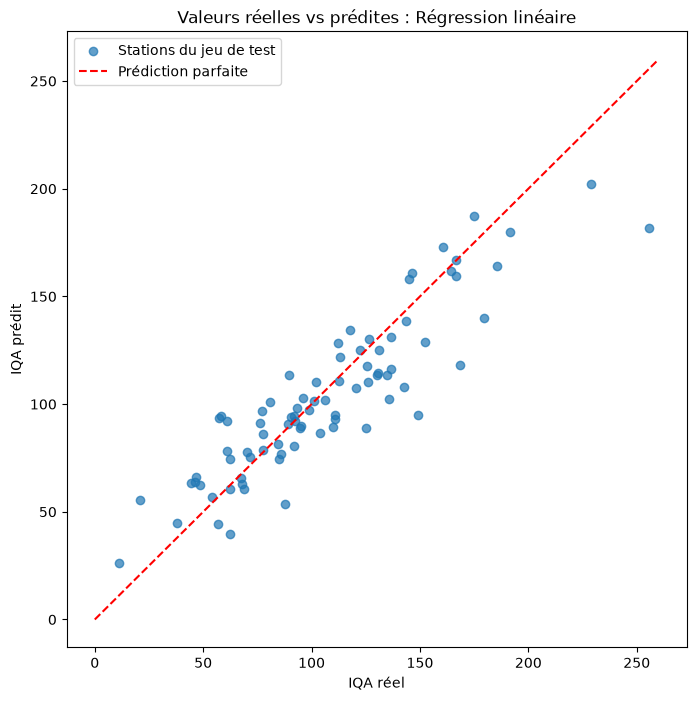

In [211]:
# Meilleur modèle = celui qui a le R² le plus élevé
meilleur_modele = tableau_performances.index[0]

fig, ax = plt.subplots(figsize=(8, 8))
ax.scatter(y_test, predictions[meilleur_modele], alpha=0.7, label="Stations du jeu de test")
ax.plot([0, 260], [0, 260], color="red", ls="--", label="Prédiction parfaite")
ax.set_title(f"Valeurs réelles vs prédites : {meilleur_modele}")
ax.set_xlabel("IQA réel")
ax.set_ylabel("IQA prédit")
ax.legend()
plt.show()

### Importance des features

L'importance est lue dans les coefficients de la régression linéaire (meilleur modèle). Les features numériques étant normalisées, leurs coefficients sont comparables : un coefficient de +10 signifie que l'IQA augmente de 10 points quand la variable augmente d'un quelconque.

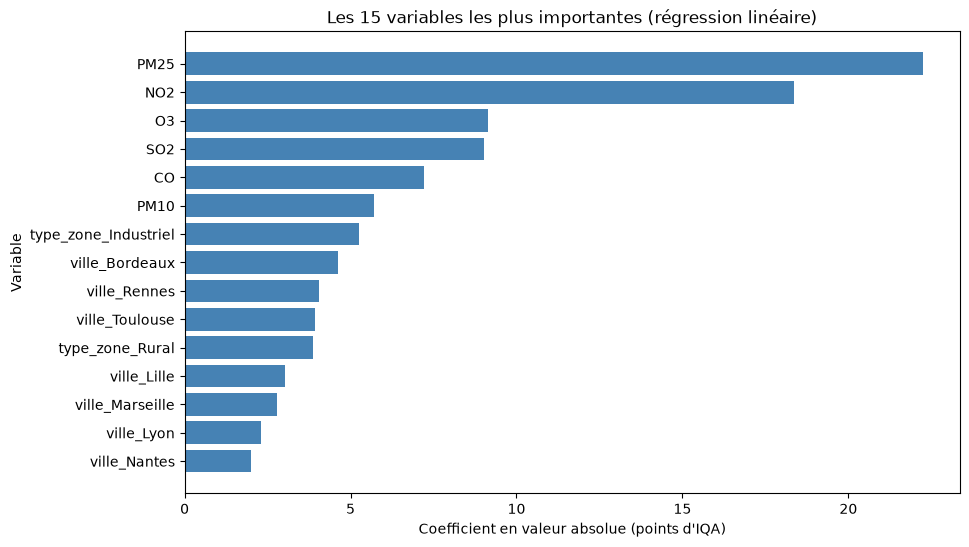

In [212]:
# Coefficients de la régression linéaire, classés par valeur absolue
coefficients = pd.Series(modeles["Régression linéaire"].coef_, index=X.columns)
top_15 = coefficients.abs().sort_values().tail(15)

fig, ax = plt.subplots(figsize=(10, 6))
ax.barh(top_15.index, top_15.values, color="steelblue")
ax.set_title("Les 15 variables les plus importantes (régression linéaire)")
ax.set_xlabel("Coefficient en valeur absolue (points d'IQA)")
ax.set_ylabel("Variable")
plt.show()

## 5.4 Interprétation et conclusion

**Quel modèle est le plus performant et pourquoi ?**
* La **régression linéaire** est la meilleure : R² = 0.798, MAE = 15.9, RMSE = 20.5. Elle explique environ 80 % de la variation de l'IQA, avec une erreur moyenne d'environ 16 points sur une échelle où l'écart-type est de 45.5.
* L'arbre de décision est nettement moins bon (R² = 0.601, MAE = 22.5).

**Quelles variables sont les plus déterminantes ?**
* **PM25** domine nettement : +23.7 points d'IQA par écart-type.
* **NO2** arrive en deuxième (+17.5), puis O3 (+8.3) et SO2 (+7.7).
  
**Limites et améliorations possibles**
* **Améliorer le jeu de données** : 402 stations et 81 lignes de test. Les scores peuvent varier selon le découpage.
* **Imputation** : 29 à 45 valeurs par variable ont été remplacées par la médiane ou la moyenne, ce qui atténue les liens réels entre variables.